# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python)  

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [1]:
# importar librerías
import pandas as pd
import numpy as np
from statsmodels.stats.proportion import proportions_ztest

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# cargar archivos csv
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')

In [3]:
# explorar dataset orders
orders.info() 
display(orders.describe().T)
display(orders.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


,count,mean,std,min,25%,50%,75%,max
cantidad,25050.0,7.092735,296.277003,-2.00,1.0000,2.000,2.0000,20000.00
precio_unitario,25050.0,259.305549,138.726461,20.03,138.3775,258.715,380.3325,499.96
monto_descuento,25050.0,4.500798,5.223010,0.00,0.0000,0.000,10.0000,15.00
monto_total,25100.0,2072.679584,98949.949719,-492.65,180.5075,341.750,518.5800,8840200.00


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


### 🔍 Hallazgo dataset orders  
---  
Después de explorar el dataset se encuentra lo siguiente:  
- Existen nulos en las columnas país, dispositivo, fuente_referencia, nombre_producto, categoría_producto, cantidad, precio_unitario y monto_descuento  
- La columna fecha_hora_pedido aparece como object y debe ser datetime  
- Hay valores muy altos en cantidad y monto_total
---

In [4]:
# explorar dataset catalog
catalog.info() 
display(catalog.describe().T)
display(catalog.head(7))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes


,count,mean,std,min,25%,50%,75%,max
costo_unitario,7.0,102.252857,111.011563,10.12,16.905,25.21,182.975,280.68


,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"
5,Sneakers-Urban-42,Moda,17.21,Greene-Smith
6,Jacket-Winter-M,Moda,189.31,Mcmillan-Rhodes


### 🔍 Hallazgo dataset catalog  
---  
El dataset no tiene ninguna observación, está limpio y no requiere ningún tipo de corrección  

---

In [5]:
# explorar dataset marketing
marketing.info() 
display(marketing.describe().T)
display(marketing.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


,count,mean,std,min,25%,50%,75%,max
gasto,1620.0,1772.74292,734.43294,501.11,1128.03,1782.425,2420.685,2999.36


,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


### 🔍 Hallazgo dataset marketing  
---  
Después de la exploración encontramos lo siguiente:
- Existen nulos en la columna canal
- La fecha aparece como object hay que pasarla a datetime
---

---

In [6]:
# Copiar orders a orders_clean para trabajar en ese dataset
orders_clean = orders.copy()
orders_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


In [7]:
# Copiar catalog a catalog_clean para trabajar en ese dataset
catalog_clean = catalog.copy()
catalog_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes


In [8]:
# Copiar marketing a marketing_clean para trabajar en ese dataset
marketing_clean = marketing.copy()
marketing_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets  
- Validar y convertir fechas al formato correcto ✅    
- Revisar variables numéricas (sin negativos o ceros inválidos) ✅   
- Verificar consistencia de montos ✅  
- Eliminar duplicados ✅  
- Revisar variables categóricas ✅ 
---

### 🖋️ Acción  
---  
Se corrigen las columnas **fecha_hora_pedido** en el dataset **orders** y la **fecha** en **marketing** a datetime  

---

In [9]:
# Corregir fecha_hora_pedido en orders pasando de object a datetime
orders_clean['fecha_hora_pedido'] = pd.to_datetime(orders_clean['fecha_hora_pedido'], errors = 'coerce')
orders_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25100 non-null  object        
 1   id_usuario          25100 non-null  object        
 2   fecha_hora_pedido   25100 non-null  datetime64[ns]
 3   pais                24800 non-null  object        
 4   dispositivo         25080 non-null  object        
 5   fuente_referencia   25070 non-null  object        
 6   nombre_producto     25070 non-null  object        
 7   categoria_producto  25020 non-null  object        
 8   cantidad            25050 non-null  float64       
 9   precio_unitario     25050 non-null  float64       
 10  monto_descuento     25050 non-null  float64       
 11  monto_total         25100 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.3+ MB


In [10]:
# Verificar que sea un único año en orders
orders_clean['fecha_hora_pedido'].dt.year.value_counts()

2025    25100
Name: fecha_hora_pedido, dtype: int64

In [11]:
# Corregir fecha en marketing pasando de object a datetime
marketing_clean['fecha'] = pd.to_datetime(marketing_clean['fecha'], errors = 'coerce')
marketing_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1620 non-null   datetime64[ns]
 1   pais        1620 non-null   object        
 2   id_campaña  1620 non-null   object        
 3   canal       1519 non-null   object        
 4   gasto       1620 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 63.4+ KB


### 🔍 Hallazgo   
---  
Se detectan **50 registros en orders sin cantidad ni precio unitario**

---

### 🖋️ Acción   
---  
Para corregirlos traemos el **costo_unitario** de cada uno de ellos del **catalog**, dividimos el **monto total entre el costo_unitario y redondeamos al entero inferior para obtener la cantidad**. En caso de ser 0, tomamos la decisión de eliminarlos pues es indicativo de que se está vendiendo por debajo del costo.  
**Reemplazamos los nulos** que hay en **categoria_producto** con las del catalog, asumimos que no hay **descuento** en dichos registros y se **los ponemos en 0**.  
Finalmente **desechamos columnas temporales** y reintegramos dichos registros al dataset orders_clean  

---

In [12]:
# Corregir nulos en orders
orders_nulos = orders_clean[orders_clean['cantidad'].isna()].copy()
print(f"Total de registros con cantidad nula: {len(orders_nulos)}")

# Realizar left merge usando nombre_producto como llave incluyendo categoria_producto y costo_unitario desde el catalog
orders_nulos = orders_nulos.merge(
    catalog_clean[['nombre_producto', 'categoria_producto', 'costo_unitario']], 
    on='nombre_producto', how='left', suffixes=('_original', '_catalogo'))

# Rellenar los nulos de la categoría original usando la categoría del catálogo
orders_nulos['categoria_producto'] = orders_nulos['categoria_producto_original'].fillna(
    orders_nulos['categoria_producto_catalogo'])

# Limpiar las columnas temporales que ya no necesitamos
orders_nulos = orders_nulos.drop(
    columns=['categoria_producto_original', 'categoria_producto_catalogo'])

# Cálculo de la cantidad basado en el costo unitario tomando el entero inferior
orders_nulos["cantidad"] = np.floor(orders_nulos["monto_total"] / orders_nulos["costo_unitario"])

# Filtrar el dataset para conservar únicamente las filas donde la cantidad sea mayor a 0
orders_nulos = orders_nulos[orders_nulos["cantidad"] > 0].copy()

# Cálculo del precio unitario basado en la nueva cantidad previamente calculada
orders_nulos["precio_unitario"] = (orders_nulos["monto_total"] / orders_nulos["cantidad"])

# Reemplazar monto_descuento por 0, quitar columna temporal de costo_unitario y reset de index
orders_nulos["monto_descuento"] = orders_nulos["monto_descuento"].fillna(0)
orders_nulos = orders_nulos.drop(columns=["costo_unitario"]).reset_index(drop=True)

# Verificar cuántos registros quedan
print(f"Registros limpios restantes en orders_nulos: {len(orders_nulos)}")

Total de registros con cantidad nula: 50
Registros limpios restantes en orders_nulos: 46


In [13]:
# Regresar información limpia al dataset orders_clean
# Concatenar orders_clean con los registros limpios de orders_nulos
orders_clean = pd.concat([orders_clean, orders_nulos], ignore_index=True)

# Resetear el índice 
orders_clean = orders_clean.reset_index(drop=True)

# Verificar que el total de filas sea el correcto
print(f"Total final de registros en orders_clean: {len(orders_clean)}")
orders_clean.info()

Total final de registros en orders_clean: 25146
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25146 entries, 0 to 25145
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25146 non-null  object        
 1   id_usuario          25146 non-null  object        
 2   fecha_hora_pedido   25146 non-null  datetime64[ns]
 3   pais                24846 non-null  object        
 4   dispositivo         25126 non-null  object        
 5   fuente_referencia   25116 non-null  object        
 6   nombre_producto     25116 non-null  object        
 7   categoria_producto  25066 non-null  object        
 8   cantidad            25096 non-null  float64       
 9   precio_unitario     25096 non-null  float64       
 10  monto_descuento     25096 non-null  float64       
 11  monto_total         25146 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usa

In [14]:
# Revisar variables numéricas

# Cuenta cuántos valores son menores a 0 en la columna cantidad
negativos_cantidad = (orders_clean['cantidad'] < 0).sum()

# Muestra solo las filas donde cantidad es menor a 0
filas_negativas = orders_clean[orders_clean['cantidad'] < 0]
display(filas_negativas)
print(f"Cantidad de valores negativos en 'cantidad': {negativos_cantidad}")

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
266,order_266,user_7011,2025-03-13,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-2.0,101.31,10.0,-192.62
267,order_267,user_1087,2025-05-07,NaN,desktop,social,Phone-Pro-128GB,Electronica,-1.0,43.50,5.0,-38.50
268,order_268,user_84,2025-02-19,NaN,desktop,organic,Phone-Pro-128GB,Electronica,-1.0,497.65,5.0,-492.65
269,order_269,user_3323,2025-05-25,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-1.0,423.53,0.0,-423.53


Cantidad de valores negativos en 'cantidad': 4


In [15]:
# Cuenta cuántos valores son menores a 0 en la columna monto_total
negativos_monto_total = (orders_clean['monto_total'] < 0).sum()

# Muestra solo las filas donde monto_total es menor a 0
filas_negativas = orders_clean[orders_clean['monto_total'] < 0]
display(filas_negativas)
print(f"Cantidad de valores negativos en 'monto_total': {negativos_monto_total}")

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
266,order_266,user_7011,2025-03-13,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-2.0,101.31,10.0,-192.62
267,order_267,user_1087,2025-05-07,NaN,desktop,social,Phone-Pro-128GB,Electronica,-1.0,43.50,5.0,-38.50
268,order_268,user_84,2025-02-19,NaN,desktop,organic,Phone-Pro-128GB,Electronica,-1.0,497.65,5.0,-492.65
269,order_269,user_3323,2025-05-25,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-1.0,423.53,0.0,-423.53


Cantidad de valores negativos en 'monto_total': 4


### 🔍 Hallazgo  
---
Se detecta que los 4 registros con **cantidad negativa** son los mismos registros que los de **monto_total** negativo, además de no contener información del país

---

### 🖋️ Acción  
---  
Al representar los 4 registros con cantidad negativa un porcentaje muy bajo (el **0.16% del total**), se procede a **filtrarlos** pues no sabemos si fue error de captura o una devolución

---

In [16]:
# Filtrar los registros negativos de orders_clean conservando solo cantidades mayores o iguales a 0
orders_clean = orders_clean[orders_clean['cantidad'] >= 0]

# Verificar que ya no queden negativos
print(f"Valores negativos restantes en cantidad:",(orders_clean['cantidad'] < 0).sum())
print(f"Valores negativos restantes en monto_total:",(orders_clean['monto_total'] < 0).sum())

print(f"Valores en cero en cantidad:",(orders_clean['cantidad'] == 0).sum())
print(f"Valores en cero en precio_unitario:",(orders_clean['precio_unitario'] == 0).sum())

Valores negativos restantes en cantidad: 0
Valores negativos restantes en monto_total: 0
Valores en cero en cantidad: 0
Valores en cero en precio_unitario: 0


In [17]:
# Verificar consistencia de cantidad pues tienen valores muy altos, usamos el método IQR
Q1 = orders_clean['cantidad'].quantile(0.25)
Q3 = orders_clean['cantidad'].quantile(0.75)
IQR = Q3 - Q1
lim_sup_cant = Q3 + 1.5 * IQR
outliers_cant = orders_clean[orders_clean['cantidad'] > lim_sup_cant]
print(f"Registros con cantidad muy alta mayor al límite superior (>{lim_sup_cant:.2f}): {len(outliers_cant)}")

Registros con cantidad muy alta mayor al límite superior (>3.50): 43


In [18]:
# Verificar consistencia de monto_total pues tienen valores muy altos usando el método IQR
Q1 = orders_clean['monto_total'].quantile(0.25)
Q3 = orders_clean['monto_total'].quantile(0.75)
IQR = Q3 - Q1
lim_sup_monto = Q3 + 1.5 * IQR
outliers_monto = orders_clean[orders_clean['monto_total'] > lim_sup_monto]
print(f"Registros con monto_total muy alto mayor al límite superior (>{lim_sup_monto:.2f}): {len(outliers_monto)}")

Registros con monto_total muy alto mayor al límite superior (>1025.66): 10


In [19]:
# Filtrar los registros que superen cualquiera de los dos límites y mostrarlos
registros_altos = orders_clean[
    (orders_clean['cantidad'] > lim_sup_cant) | 
    (orders_clean['monto_total'] > lim_sup_monto)]

# Mostrar los registros encontrados
display(registros_altos)
print(f"Total de registros con valores altos: {len(registros_altos)}")

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
3521,order_3521,user_5812,2025-02-03,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,10000.0,43.140000,0.0,431400.00
3522,order_3522,user_3575,2025-03-29,Argentina,desktop,social,Laptop-Gaming-16GB,Electronica,10000.0,280.550000,0.0,2805500.00
3586,order_3586,user_3380,2025-02-03,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,10000.0,490.350000,0.0,4903500.00
3643,order_3643,user_4440,2025-01-07,Colombia,desktop,social,Laptop-Gaming-16GB,Electronica,10000.0,238.150000,0.0,2381500.00
3656,order_3656,user_884,2025-01-01,Argentina,mobile,organic,Laptop-Gaming-16GB,Electronica,20000.0,297.660000,0.0,5953200.00
3668,order_3668,user_7270,2025-06-24,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,20000.0,348.310000,0.0,6966200.00
3689,order_3689,user_6566,2025-06-16,mexico,desktop,paid_search,Laptop-Gaming-16GB,Electronica,10000.0,87.690000,0.0,876900.00
3722,order_3722,user_4723,2025-05-09,Argentina,mobile,paid_search,Laptop-Gaming-16GB,Electronica,20000.0,442.010000,0.0,8840200.00
3726,order_3726,user_2536,2025-02-12,Colombia,desktop,social,Laptop-Gaming-16GB,Electronica,20000.0,290.850000,0.0,5817000.00
3748,order_3748,user_7096,2025-02-23,Mexico,desktop,organic,Laptop-Gaming-16GB,Electronica,10000.0,336.930000,0.0,3369300.00


Total de registros con valores altos: 43


### 🔍 Hallazgo  
---  
Por el método de IQR se detecta que hay **10 registros** con **cantidad muy alta** (mayores o iguales a 10,000) y que son los mismos registros que los de **monto_total** alto, se procede a su limpieza. Hay otros 33 registros con valores altos en cantidad que se dejan intactos pues son razonablemente lógicos para el negocio

---

###  🖋️ Acción  
---  
Los 10 registros con cantidad muy alta representan un porcentaje muy bajo (el **0.04% del total**), se procede a **filtrarlos** pues probablemente fue un error de captura y nos van a causar problemas con nuestras métricas finales. Los otros 33 se quedan en el dataset  

---

In [20]:
# Filtrar los registros con valores muy altos de cantidad y monto_total de orders_clean conservando solo cantidades menores a 10,000
orders_clean = orders_clean[orders_clean['cantidad'] < 10000]

# Verificar que ya no queden valores altos
print(f"Valores altos restantes en cantidad:",(orders_clean['cantidad'] >= 10000).sum())

# Reset Index
orders_clean = orders_clean.reset_index(drop=True)

# Explorar dataset orders_clean limpio de negativos y outliers
display(orders_clean.describe().T)
display(orders_clean.info())

Valores altos restantes en cantidad: 0


,count,mean,std,min,25%,50%,75%,max
cantidad,25082.0,1.535563,1.101535,1.000000,1.0000,2.00,2.0000,57.00
precio_unitario,25082.0,258.975323,138.870991,10.141818,137.9075,258.20,380.1150,499.96
monto_descuento,25082.0,4.494259,5.222262,0.000000,0.0000,0.00,10.0000,15.00
monto_total,25082.0,385.948550,255.740052,5.240000,180.6025,341.71,518.0275,999.89


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25082 entries, 0 to 25081
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25082 non-null  object        
 1   id_usuario          25082 non-null  object        
 2   fecha_hora_pedido   25082 non-null  datetime64[ns]
 3   pais                24786 non-null  object        
 4   dispositivo         25062 non-null  object        
 5   fuente_referencia   25052 non-null  object        
 6   nombre_producto     25052 non-null  object        
 7   categoria_producto  25052 non-null  object        
 8   cantidad            25082 non-null  float64       
 9   precio_unitario     25082 non-null  float64       
 10  monto_descuento     25082 non-null  float64       
 11  monto_total         25082 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.3+ MB


None

### 🔍 Hallazgo  
---  
- Se detectan **100 registros duplicados** en el dataset **orders**
- Además de los **nulos** ya detectados en las columnas país, dispositivo, fuente_referencia, nombre_producto y categoria_producto
- Se detectan países con la **primera letra en minúscula**
- Se detectan registros con **Electrónica con acento y sin acento**

---

### 🖋️ Acción  
---  
- Procedemos a **eliminar los 100 registros duplicados** en el dataset orders  
- Los **nulos** en país, dispositivo, fuente_referencia, nombre_producto y categoria_producto son **sustituidos por Desconocido**
- Se **corrigen** los nombres de los países que tienen la primera letra en minúscula a la **primera en mayúscula**
- En categoría se corrigen los registros de Electrónica (con acento) se pasan a **Electronica (sin acento) pues la mayoría está sin acento**

---

In [21]:
# Nulos
print("Cantidad de Nulos por Columna para el dataset orders:")
print(orders_clean.isna().sum())
print()
print("Porcentaje (%) de Nulos por Columna para el dataset orders:")
print(orders_clean.isna().mean()*100)

Cantidad de Nulos por Columna para el dataset orders:
id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                  296
dispositivo            20
fuente_referencia      30
nombre_producto        30
categoria_producto     30
cantidad                0
precio_unitario         0
monto_descuento         0
monto_total             0
dtype: int64

Porcentaje (%) de Nulos por Columna para el dataset orders:
id_pedido             0.000000
id_usuario            0.000000
fecha_hora_pedido     0.000000
pais                  1.180129
dispositivo           0.079738
fuente_referencia     0.119608
nombre_producto       0.119608
categoria_producto    0.119608
cantidad              0.000000
precio_unitario       0.000000
monto_descuento       0.000000
monto_total           0.000000
dtype: float64


In [22]:
# Eliminar Duplicados
print("Duplicados en Orders:", orders_clean.duplicated().sum())
print("Duplicados en Marketing:", marketing_clean.duplicated().sum())
orders_clean = orders_clean.drop_duplicates(subset = "id_pedido", keep = "first").reset_index(drop=True)
print("Duplicados en Orders después de eliminarlos:", orders_clean.duplicated().sum())

Duplicados en Orders: 100
Duplicados en Marketing: 0
Duplicados en Orders después de eliminarlos: 0


In [23]:
# Revisar variables categóricas en orders
columnas_categoricas = ["pais", "dispositivo", "fuente_referencia", "nombre_producto", "categoria_producto"]
for col in columnas_categoricas :
    print(f" {col} ")
    print(orders_clean[col].value_counts(dropna=False))

 pais 
Colombia     7477
Mexico       7473
Argentina    7255
mexico        862
colombia      823
argentina     796
NaN           296
Name: pais, dtype: int64
 dispositivo 
desktop    12700
mobile     12262
NaN           20
Name: dispositivo, dtype: int64
 fuente_referencia 
social         8396
organic        8284
paid_search    8272
NaN              30
Name: fuente_referencia, dtype: int64
 nombre_producto 
Blender-XL-Red          4179
Vacuum-Pro-Black        4176
Jacket-Winter-M         4173
Sneakers-Urban-42       4148
Laptop-Gaming-16GB      2771
Tablet-Standard-64GB    2769
Phone-Pro-128GB         2736
NaN                       30
Name: nombre_producto, dtype: int64
 categoria_producto 
Hogar          8355
Moda           8321
Electronica    8265
NaN              30
Electrónica      11
Name: categoria_producto, dtype: int64


In [24]:
# Rellenar nulos en las columnas categóricas
for col in columnas_categoricas:
    orders_clean[col] = orders_clean[col].fillna("Desconocido")
    
# Poner la primera letra mayúscula en país para estandarizar
orders_clean["pais"] = orders_clean["pais"].str.capitalize()

# Corregir Electrónica
orders_clean["categoria_producto"] = orders_clean['categoria_producto'].replace('Electrónica', 'Electronica')

# Verificar el resultado en las categorías únicas
print(orders_clean['categoria_producto'].value_counts(dropna=False))

# Verificar que ya no queden nulos
print("Verificación de Nulos en columnas categóricas")
print(orders_clean[columnas_categoricas].isna().sum())

Hogar          8355
Moda           8321
Electronica    8276
Desconocido      30
Name: categoria_producto, dtype: int64
Verificación de Nulos en columnas categóricas
pais                  0
dispositivo           0
fuente_referencia     0
nombre_producto       0
categoria_producto    0
dtype: int64


In [25]:
# Verificar que no haya diferencias en los nombres de los países y que los nulos sean sustituidos por "Desconocido"
print(orders_clean["pais"].value_counts(dropna=False))

Mexico         8335
Colombia       8300
Argentina      8051
Desconocido     296
Name: pais, dtype: int64


In [26]:
# Verificar dataset limpio
print("Verificación del dataset orders limpio")
orders_clean.info() 

Verificación del dataset orders limpio
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24982 entries, 0 to 24981
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           24982 non-null  object        
 1   id_usuario          24982 non-null  object        
 2   fecha_hora_pedido   24982 non-null  datetime64[ns]
 3   pais                24982 non-null  object        
 4   dispositivo         24982 non-null  object        
 5   fuente_referencia   24982 non-null  object        
 6   nombre_producto     24982 non-null  object        
 7   categoria_producto  24982 non-null  object        
 8   cantidad            24982 non-null  float64       
 9   precio_unitario     24982 non-null  float64       
 10  monto_descuento     24982 non-null  float64       
 11  monto_total         24982 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.3+ 

In [27]:
# Revisar variables categóricas en marketing
print(marketing_clean["canal"].value_counts(dropna=False))

paid_search    507
organic        506
social         506
NaN            101
Name: canal, dtype: int64


### 🔍 Hallazgo  
---
- Se detectan **101 registros nulos** en la columna **canal** del dataset **marketing**

---

### 🖋️ Acción   
---  
- Los **nulos** en canal de marketing son **sustituidos por Desconocido**

---

In [28]:
# Rellenar nulos en columna canal en dataset marketing
marketing_clean["canal"] = marketing_clean["canal"].fillna("Desconocido")

# Verificar que ya no queden nulos
print("Verificación de Nulos en marketing:", marketing_clean["canal"].isna().sum())
print()
print("Verificación del dataset marketing limpio")
marketing_clean.info() 
print(marketing_clean["canal"].value_counts(dropna=False))

Verificación de Nulos en marketing: 0

Verificación del dataset marketing limpio
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1620 non-null   datetime64[ns]
 1   pais        1620 non-null   object        
 2   id_campaña  1620 non-null   object        
 3   canal       1620 non-null   object        
 4   gasto       1620 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 63.4+ KB
paid_search    507
organic        506
social         506
Desconocido    101
Name: canal, dtype: int64


### 🔍 Hallazgo  
---  
- Se verifica que los **montos totales sean consistentes**, se encuentra que **coinciden** con la fórmula de monto_total = cantidad * precio_unitario - monto_descuento por lo tanto están **listos para ser exportados**

---

In [29]:
# Calcular el monto total esperado
monto_calculado = (orders_clean['cantidad'] * orders_clean['precio_unitario']) - orders_clean['monto_descuento']

# Comprobar si coincide con el monto_total real permitiendo una tolerancia mínima por decimales
diferencias = ~np.isclose(orders_clean['monto_total'], monto_calculado, atol=0.01)

# Filtrar y contar cuántos registros NO coinciden
registros_con_diferencia = orders_clean[diferencias]
print(f"Total de registros donde el monto_total no coincide: {len(registros_con_diferencia)}")

# Si hay diferencias, mostrarlas
if len(registros_con_diferencia) > 0:
    display(registros_con_diferencia[['id_pedido', 'cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']])
else:
    print("Todos los montos totales coinciden con la fórmula")

Total de registros donde el monto_total no coincide: 0
Todos los montos totales coinciden con la fórmula


In [30]:
orders_clean.head(10)

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28
5,order_5,user_2792,2025-04-22,Mexico,desktop,organic,Tablet-Standard-64GB,Electronica,1.0,179.34,0.0,179.34
6,order_6,user_2802,2025-03-15,Colombia,mobile,organic,Blender-XL-Red,Hogar,2.0,163.59,0.0,327.19
7,order_7,user_1083,2025-05-01,Mexico,desktop,organic,Tablet-Standard-64GB,Electronica,2.0,373.68,0.0,747.35
8,order_8,user_2352,2025-03-01,Argentina,desktop,paid_search,Laptop-Gaming-16GB,Electronica,2.0,477.27,5.0,949.54
9,order_9,user_7001,2025-05-31,Mexico,mobile,organic,Sneakers-Urban-42,Moda,1.0,339.30,5.0,334.30


---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [31]:
# exportar datasets
orders_clean.to_csv('orders_clean.csv', index=False, sep=';', decimal='.', encoding="utf-8-sig")
catalog_clean.to_csv('catalog_clean.csv', index=False, sep=';', decimal='.')
marketing_clean.to_csv('marketing_clean.csv', index=False, sep=';', decimal='.', encoding="utf-8-sig")

---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1:
 Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)? 
- ¿Cuál es el costo total? 
- ¿Cuánto se ha invertido en marketing? 
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden? 
- ¿Cuál es la cantidad promedio de productos por orden? 
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal? 


In [32]:
# Merge orders y catalog bajo nombre_producto
orders_with_cost = orders_clean.merge(catalog_clean[["nombre_producto", "costo_unitario"]], on= "nombre_producto", how= "left")

In [33]:
orders_with_cost.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,costo_unitario
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37,189.31
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86,25.21
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99,176.64
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87,25.21
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28,176.64


In [34]:
# Parte 1 Rentabilidad del Negocio
# Ingreso Total (Revenue) : Suma del monto_total
ingreso_total = orders_with_cost['monto_total'].sum()

# Costo Total: multiplicar la cantidad vendida por el costo unitario de cada producto
costo_total = (orders_with_cost['cantidad'] * orders_with_cost['costo_unitario']).sum()

# Gasto Total en Marketing : Suma del gasto en marketing
gasto_marketing = marketing_clean['gasto'].sum()

# Ganancia / (Profit): Ingreso Neto menos el costo_total - gasto_marketing
ingreso_bruto = ingreso_total - costo_total
ingreso_neto = ingreso_bruto - gasto_marketing

# Margen % : Ingreso Neto / Ingresos x 100
margen = (ingreso_neto / ingreso_total ) * 100

# Mostrar los KPI's
print("   Rentabilidad del Negocio")
print(f"Ingreso Total (Revenue): ${ingreso_total:,.0f}")
print(f"Costo Total:             ${costo_total:,.0f}")
print(f"Utilidad Bruta:          ${ingreso_bruto:,.0f}")
print(f"Inversión en Marketing:  ${gasto_marketing:,.0f}")
print(f"Utilidad Neta:           ${ingreso_neto:,.0f}")
print(f"Margen de Ganancia:      %{margen:,.1f}")

   Rentabilidad del Negocio
Ingreso Total (Revenue): $9,643,566
Costo Total:             $3,848,651
Utilidad Bruta:          $5,794,915
Inversión en Marketing:  $2,871,844
Utilidad Neta:           $2,923,071
Margen de Ganancia:      %30.3


### 💰 Resultados Financieros y de Ventas  
---  
**📊 Rentabilidad del negocio**
- Ingreso Total (Revenue): **\$9,643,566**  
- Costo Total:             **\$3,848,651**  
- Utilidad (Profit) Bruta: **\$5,794,915**  
- Inversión en Marketing:  **\$2,871,844**  
- Utilidad (Profit) Neta:  **\$2,923,071**  
- Margen Neto de Ganancia: **30.3%**

---
**Se concluye que el negocio de RappiPlus es rentable con un margen del 30.3% lo que para una plataforma de este tipo está en los límites aceptables** ✅

---

**📈 Comportamiento de ventas**
- Ticket promedio por orden: **\$386.02**
- Cantidad promedio de productos por orden: **1.54**
- Producto más vendido: **Sneakers-Urban-42 (6,664 unidades)**
- Gasto en marketing por canal:  
**social \$918,043.21**  
**organic \$913,533.01**  
**paid_search \$863,088.21**  
**Desconocido \$177,179.10**  

---  
Se tiene un ticket promedio equilibrado con un valor medio suficiente, la cantidad promedio de productos por orden es de un poco más de 1 unidad por orden, considerando el tipo de categorías se puede decir que es razonable aunque un poco baja. Los productos más vendido son los **Sneakers-Urban-42 con 6,664 unidades**, lo que sugiere que la categoría moda puede ser un gancho para compra. El gasto en los diferentes canales es bastante equilibrado destacando el de **"social"**, se sugiere corregir las asignaciones del gasto pues hay fuga o falta de trazabilidad en algunas campañas.  

---

In [35]:
# Parte 2 Comportamiento de Ventas
# Ticket Promedio: El monto promedio pagado por orden
ticket_promedio = orders_with_cost['monto_total'].mean()

# Cantidad Promedio de productos por orden
cantidad_promedio = orders_with_cost['cantidad'].mean()

# Producto más vendido (por unidades totales acumuladas)
producto_mas_vendido = orders_with_cost.groupby('nombre_producto')['cantidad'].sum().idxmax()
total_unidades_producto = orders_with_cost.groupby('nombre_producto')['cantidad'].sum().max()

# Gasto en marketing por canal
gasto_por_canal = marketing_clean.groupby('canal')['gasto'].sum().sort_values(ascending=False)

# Mostrar resultados de comportamiento
print("    Comportamiento de Ventas")
print(f"Ticket Promedio:            ${ticket_promedio:,.2f}")
print(f"Cantidad Promedio por Orden: {cantidad_promedio:.2f}")
print(f"Producto más vendido:        {producto_mas_vendido} ({total_unidades_producto:,.0f} unidades)")
print("\nGasto en marketing por canal:")
display(gasto_por_canal)

    Comportamiento de Ventas
Ticket Promedio:            $386.02
Cantidad Promedio por Orden: 1.54
Producto más vendido:        Sneakers-Urban-42 (6,664 unidades)

Gasto en marketing por canal:


canal
social         918043.21
organic        913533.01
paid_search    863088.21
Desconocido    177179.10
Name: gasto, dtype: float64

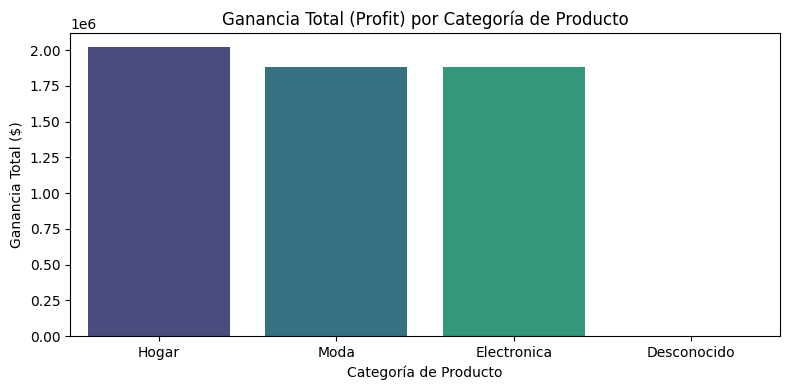

,categoria_producto,profit_orden
0,Hogar,2019479.11
1,Moda,1882821.01
2,Electronica,1880352.12
3,Desconocido,0.00


In [36]:
# Métricas adicionales
# Calcular el profit por orden 
orders_with_cost['profit_orden'] = (orders_with_cost['monto_total']) - (orders_with_cost['cantidad'] * orders_with_cost['costo_unitario'])

# Agrupar por categoría de producto y ordenar de mayor a menor
profit_por_categoria = orders_with_cost.groupby('categoria_producto')['profit_orden'].sum().sort_values(ascending=False).reset_index()

# Graficar
plt.figure(figsize=(8, 4))
sns.barplot(data=profit_por_categoria, x='categoria_producto', y='profit_orden', palette='viridis')
plt.title('Ganancia Total (Profit) por Categoría de Producto')
plt.xlabel('Categoría de Producto')
plt.ylabel('Ganancia Total ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
display(profit_por_categoria)

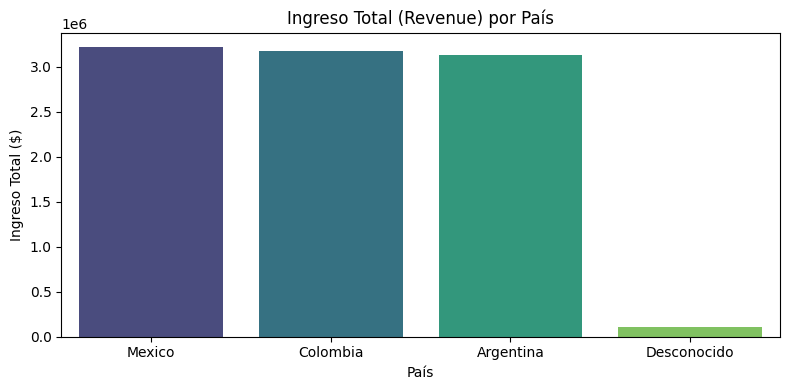

,pais,monto_total
0,Mexico,3217211.21
1,Colombia,3180705.07
2,Argentina,3133661.90
3,Desconocido,111988.05


In [37]:
# Revenue por país
revenue_por_pais = orders_with_cost.groupby('pais')['monto_total'].sum().sort_values(ascending=False).reset_index()

# Graficar 
plt.figure(figsize=(8, 4))
sns.barplot(data=revenue_por_pais, x='pais', y='monto_total', palette='viridis')
plt.title('Ingreso Total (Revenue) por País')
plt.xlabel('País')
plt.ylabel('Ingreso Total ($)')
plt.tight_layout()
plt.show()

display(revenue_por_pais)

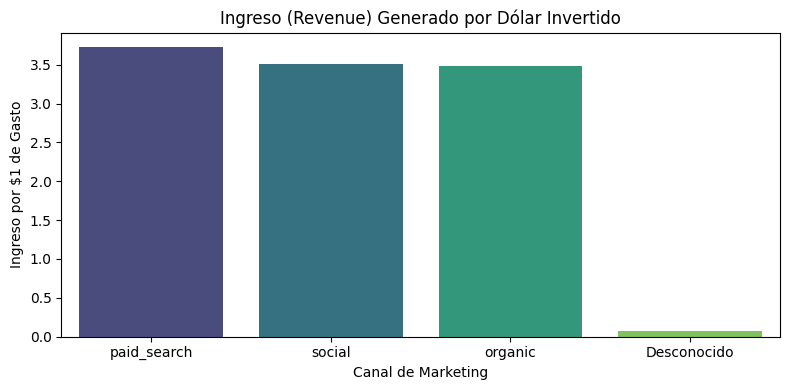

,canal,revenue_total,gasto,revenue_por_dolar
2,paid_search,3216056.97,863088.21,3.726220
3,social,3228371.75,918043.21,3.516579
1,organic,3186874.89,913533.01,3.488516
0,Desconocido,12262.62,177179.10,0.069210


In [38]:
# Agrupar ingresos por fuente_referencia
revenue_canal = orders_with_cost.groupby('fuente_referencia')['monto_total'].sum().reset_index()
revenue_canal.rename(columns={'fuente_referencia': 'canal', 'monto_total': 'revenue_total'}, inplace=True)

# Agrupar gasto total por canal
gasto_canal = marketing_clean.groupby('canal')['gasto'].sum().reset_index()

# Unir ambas tablas para calcular la eficiencia (Revenue / Gasto)
eficiencia_canal = revenue_canal.merge(gasto_canal, on='canal', how='inner')
eficiencia_canal['revenue_por_dolar'] = eficiencia_canal['revenue_total'] / eficiencia_canal['gasto']

# Ordenar de mayor a menor eficiencia
eficiencia_canal = eficiencia_canal.sort_values(by='revenue_por_dolar', ascending=False)

# Graficar la eficiencia por canal
plt.figure(figsize=(8, 4))
sns.barplot(data=eficiencia_canal, x='canal', y='revenue_por_dolar', palette='viridis')
plt.title('Ingreso (Revenue) Generado por Dólar Invertido')
plt.xlabel('Canal de Marketing')
plt.ylabel('Ingreso por $1 de Gasto')
plt.tight_layout()
plt.show()

display(eficiencia_canal)

### 💰 Otras métricas de negocio a considerar  
---  
**📊 Utilidad (Profit) por Categoría de Producto**  
Aunque la utilidad en las diferentes categorías es similar, destaca **Hogar con \$2,019,479.11**, Moda es el siguiente y Electrónica el último, estos últimos 2 bastante cercanos entre ellos

**📊 Ingreso (Revenue) por País**  
El mayor ingreso lo tuvo **México con \$3,217,211.21** seguido de **Colombia con \$3,180,705.07** y **Argentina con \$3,133,661.90** todos muy parecidos, se recomienda identificar bien los ingresos pues hubo \$111,988.05 de los cuales se desconoce su origen  

**📊 Ingreso (Revenue) por Dólar Invertido en los diferentes Canales**  
**paid_search con \$3.73** de ingreso (revenue) por dólar invertido es el que mejor se comportó, seguido de **social con \$3.52** y **organic con \$3.49**, la estrategia de marketing genera buenos resultados en especial con los motores de búsqueda en la red por lo que hay que seguir invirtiendo

---


---

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.


---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---


In [39]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [40]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [41]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''

-- Calcular cuántos usuarios únicos llegan en cada etapa del funnel

SELECT nombre_evento,
    COUNT(DISTINCT id_usuario) AS usuarios_por_evento
FROM events

GROUP BY nombre_evento
ORDER BY case nombre_evento
    WHEN 'first_visit' THEN 1
    WHEN 'select_item' THEN 2
    WHEN 'add_to_cart' THEN 3
    WHEN 'begin_checkout' THEN 4
    WHEN 'add_payment_info' THEN 5
    WHEN 'purchase' THEN 6
    ELSE 7
END;

'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,usuarios_por_evento
0,first_visit,7796
1,select_item,7582
2,add_to_cart,7634
3,begin_checkout,7208
4,add_payment_info,6250
5,purchase,6240


### 🔍 Hallazgo  
---
Se detecta que hay un **incremento de usuarios en el paso de ir del evento select_item (7,582) a add_to_cart (7,634)** lo cual puede deberse a varios factores, entre ellos a que el usuario vaya directo al add_to_cart sin entrar a la página de detalle del producto o a que si el usuario guardó en el carro sin comprar y después regresa va directo al carrito o si el usuario agrega varios productos sin seleccionarlos. 

---

### 🖋️ Acción  
---
No se toma ninguna acción y **se deja como está**, pues es un comportamiento que se presenta en este tipo de plataformas 

---

In [42]:
# PARTE 2: Conversiones
# ======================

query_conversion = '''
-- Calcular la tasa de conversión entre etapas del funnel, en cuál se pierde la mayor cantidad de usuarios y cuál es la tasa de conversión final


WITH usr_first_visit AS (
    SELECT DISTINCT(id_usuario)
    FROM events
    WHERE nombre_evento = 'first_visit'
),
usr_select_item AS (
    SELECT DISTINCT(id_usuario)
    FROM events
    WHERE nombre_evento = 'select_item'
)
,
usr_add_to_cart AS (
    SELECT DISTINCT(id_usuario)
    FROM events
    WHERE nombre_evento = 'add_to_cart'
),
usr_begin_checkout AS (
    SELECT DISTINCT(id_usuario)
    FROM events
    WHERE nombre_evento = 'begin_checkout'
),
usr_add_payment_info AS (
    SELECT DISTINCT(id_usuario)
    FROM events
    WHERE nombre_evento = 'add_payment_info'
),
usr_purchase AS (
    SELECT DISTINCT(id_usuario)
    FROM events
    WHERE nombre_evento = 'purchase'
)
SELECT
    (SELECT COUNT(*) FROM usr_first_visit) AS first_visit,
    (SELECT COUNT(*) FROM usr_select_item) AS select_item,
    (SELECT COUNT(*) FROM usr_add_to_cart) AS add_to_cart,
    (SELECT COUNT(*) FROM usr_begin_checkout) AS begin_checkout,
    (SELECT COUNT(*) FROM usr_add_payment_info) AS add_payment_info,
    (SELECT COUNT(*) FROM usr_purchase) AS purchase,
    
ROUND(((SELECT COUNT(*)::NUMERIC FROM usr_select_item) / NULLIF((SELECT COUNT(*) FROM usr_first_visit), 0)) * 100, 2)
        AS pct_conv_select_item
,
    ROUND(((SELECT COUNT(*)::NUMERIC FROM usr_add_to_cart) / NULLIF((SELECT COUNT(*) FROM usr_select_item), 0)) * 100, 2) 
        AS pct_conv_add_to_cart,
    ROUND(((SELECT COUNT(*)::NUMERIC FROM usr_begin_checkout) / NULLIF((SELECT COUNT(*) FROM usr_add_to_cart), 0)) * 100, 2) 
        AS pct_conv_begin_checkout,
    ROUND(((SELECT COUNT(*)::NUMERIC FROM usr_add_payment_info) / NULLIF((SELECT COUNT(*) FROM usr_begin_checkout), 0)) * 100, 2) 
        AS pct_conv_add_payment_info,
    ROUND(((SELECT COUNT(*)::NUMERIC FROM usr_purchase) / NULLIF((SELECT COUNT(*) FROM usr_add_payment_info), 0)) * 100, 2) 
        AS pct_conv_purchase,
    ROUND(((((SELECT COUNT(*)::NUMERIC FROM usr_first_visit) - (SELECT COUNT(*) FROM usr_select_item))) / NULLIF((SELECT COUNT(*) FROM usr_first_visit), 0))*100, 2) 
        AS pct_dropoff_first_visit,
    ROUND(((((SELECT COUNT(*)::NUMERIC FROM usr_select_item) - (SELECT COUNT(*) FROM usr_add_to_cart))) / NULLIF((SELECT COUNT(*) FROM usr_select_item), 0))*100, 2) 
        AS pct_dropoff_select_item,
    ROUND(((((SELECT COUNT(*)::NUMERIC FROM usr_add_to_cart) - (SELECT COUNT(*) FROM usr_begin_checkout))) / NULLIF((SELECT COUNT(*) FROM usr_add_to_cart), 0))*100, 2) 
        AS pct_dropoff_add_to_cart,
    ROUND(((((SELECT COUNT(*)::NUMERIC FROM usr_begin_checkout) - (SELECT COUNT(*) FROM usr_add_payment_info))) / NULLIF((SELECT COUNT(*) FROM usr_begin_checkout), 0))*100, 2) 
        AS pct_dropoff_begin_checkout,
    ROUND(((((SELECT COUNT(*)::NUMERIC FROM usr_add_payment_info) - (SELECT COUNT(*) FROM usr_purchase))) / NULLIF((SELECT COUNT(*) FROM usr_add_payment_info), 0))*100, 2) 
        AS pct_dropoff_add_payment_info,
    ROUND(((SELECT COUNT(*)::NUMERIC FROM usr_purchase) / NULLIF((SELECT COUNT(*) FROM usr_first_visit), 0)) * 100, 2)
        AS pct_conv_final;
        
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,first_visit,select_item,add_to_cart,begin_checkout,add_payment_info,purchase,pct_conv_select_item,pct_conv_add_to_cart,pct_conv_begin_checkout,pct_conv_add_payment_info,pct_conv_purchase,pct_dropoff_first_visit,pct_dropoff_select_item,pct_dropoff_add_to_cart,pct_dropoff_begin_checkout,pct_dropoff_add_payment_info,pct_conv_final
0,7796,7582,7634,7208,6250,6240,97.26,100.69,94.42,86.71,99.84,2.74,-0.69,5.58,13.29,0.16,80.04


### 🎯 Funnel y Conversión
---

**📊 Construcción del funnel**
- **usuarios únicos que llegan a cada etapa del funnel:**     
  first_visit:      7,796  (Primera Visita)  
  select_item:      7,582  (Seleccionar Item)  
  add_to_cart:      7,634  (Agregar al Carro)  
  begin_checkout:   7,208  (Empezar Checkout)  
  add_payment_info: 6,250  (Agregar Información de Pago)  
  purchase:         6,240  (Compra)  

---

**📉 Análisis de conversión**  
- Se calcula la **tasa de conversión** entre cada paso del funnel  
  select_item: 97.26%  
  add_to_cart: 100.69%  
  begin_checkout: 94.42%  
  add_payment_info: 86.71%  
  purchase: 99.84%   
- La **etapa donde se pierde la mayor cantidad de usuarios** es entre **begin_checkout y add_payment_info y es del 13.29%**, se tendría que revisar si hay algo al agregar la información de pago que haga que el usuario abandone  
- La **tasa de conversión final** es del **80.04%** la cual es muy alta para este tipo de plataformas. La propuesta de valor de la plataforma logra retener e impulsar la intención de compra de manera eficiente
---

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**
- `users` 
- `user_activity` 

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [43]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;

'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [44]:
# Explorar tabla users
# =========================
query_users = '''

SELECT column_name, data_type
FROM information_schema.columns
WHERE table_name = 'users' AND table_schema = 'public';

'''
users = pd.read_sql(query_users, con=engine)
users.head(5)

,column_name,data_type
0,id_usuario,text
1,fecha_registro,text
2,país,text
3,dispositivo,text
4,tipo_plan,text


In [45]:
# Explorar tabla user
# =========================
query_users = '''

-- Verificar que no haya más de una fecha de registro
SELECT id_usuario,
    count(CAST(fecha_registro AS DATE)) AS conteo_signup
FROM users
GROUP BY id_usuario
HAVING count(CAST(fecha_registro AS DATE)) > 1;

'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,conteo_signup


In [46]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''

SELECT *
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [47]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''

SELECT column_name, data_type
FROM information_schema.columns
WHERE table_name = 'user_activity' AND table_schema = 'public';

'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(4)

,column_name,data_type
0,id_usuario,text
1,fecha_actividad,text
2,dias_despues_registro,bigint
3,activo,bigint


In [48]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''

-- Asignar cohorte semanal
WITH cohorte AS (
SELECT DISTINCT(id_usuario),
    DATE_TRUNC('week', MIN(CAST(fecha_registro AS DATE))) AS cohorte_semanal
FROM users
GROUP BY id_usuario
),

-- Left JOIN de activity_user a user bajo id_usuario
usuario_actividad AS(
    SELECT 
        usr.id_usuario,
        usr.cohorte_semanal,
        act.dias_despues_registro,
        act.activo
    FROM cohorte AS usr
    LEFT JOIN user_activity AS act 
        ON usr.id_usuario = act.id_usuario
    WHERE act.dias_despues_registro IN (7, 14, 21)),

-- Semanas de permanencia
permanencia AS(
SELECT
    cohorte_semanal,
    COUNT(DISTINCT id_usuario) AS usuarios_iniciales,
    COUNT(CASE WHEN dias_despues_registro = 7 AND activo = 1 THEN 1 END) AS retencion_sem1,
    COUNT(CASE WHEN dias_despues_registro  = 14 AND activo = 1 THEN 1 END) AS retencion_sem2,
    COUNT(CASE WHEN dias_despues_registro = 21 AND activo = 1 THEN 1 END) AS retencion_sem3
FROM usuario_actividad
GROUP BY cohorte_semanal)

-- Retención Semanal en porcentaje
SELECT
    TO_CHAR(cohorte_semanal, 'YYYY-WW') AS cohorte,
    usuarios_iniciales,
    retencion_sem1,
    retencion_sem2,
    retencion_sem3,
    ROUND(retencion_sem1::NUMERIC / NULLIF(usuarios_iniciales, 0), 2) as pct_sem1,
    ROUND(retencion_sem2::NUMERIC / NULLIF(usuarios_iniciales, 0), 2) as pct_sem2,
    ROUND(retencion_sem3::NUMERIC / NULLIF(usuarios_iniciales, 0), 2) as pct_sem3
FROM permanencia
GROUP BY cohorte_semanal, usuarios_iniciales, retencion_sem1, retencion_sem2, retencion_sem3
ORDER BY cohorte_semanal;
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,cohorte,usuarios_iniciales,retencion_sem1,retencion_sem2,retencion_sem3,pct_sem1,pct_sem2,pct_sem3
0,2024-53,236,99,91,95,0.42,0.39,0.40
1,2025-01,351,145,157,148,0.41,0.45,0.42
2,2025-02,362,158,138,152,0.44,0.38,0.42
3,2025-03,394,174,156,157,0.44,0.40,0.40
4,2025-04,373,155,177,149,0.42,0.47,0.40
5,2025-05,405,164,177,184,0.40,0.44,0.45
6,2025-06,364,153,145,164,0.42,0.40,0.45
7,2025-07,338,159,136,135,0.47,0.40,0.40
8,2025-08,353,149,148,151,0.42,0.42,0.43
9,2025-09,363,144,158,146,0.40,0.44,0.40


## 📈 Análisis de retención por cohortes
---
El **porcentaje de retención** a través de las 3 primeras semanas se mantiene en un rango muy estable e inusualmente **alto entre un 37% y un 47%**. Eso significa que los usuarios regresan de forma consistente semana a semana.  
A excepción de la semana de inicio, el **flujo de captación** de usuarios se mantiene a lo largo de las semanas entre **350 a 400** usuarios.  
El cohorte con mejor comportamiento a lo largo del tiempo fue el de la **semana 14** con una **retención promedio de arriba del 45%** seguido por las **semanas 4, 5 y 15**.

---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.✅

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.✅
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.
   - Encontramos que la fecha estaba como texto y aunque no influye en la prueba estadística se corrige de todas maneras    
2. **Plantear la hipótesis estadística** ✅    
3. **Aplicar el test estadístico adecuado**✅ 
4. **Interpretar el resultado** ✅  

---
### 🧪 Hipótesis estadística  
   - **H₀ (Hipótesis nula):** La tasa de conversión de compra es igual en ambas variantes
   - **H₁ (Hipótesis alternativa):** La tasa de conversión de compra es diferente en ambas variantes  
   
**Test estadístico: Prueba z** para comparar proporciones  
**Nivel de significancia alpha:** Le damos un valor de 5% (0.05)

---

In [49]:
# cargar archivos csv
experiment_checkout = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')
# explorar dataset orders
experiment_checkout.info() 
display(experiment_checkout.describe().T)
display(experiment_checkout.head(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB


,count,mean,std,min,25%,50%,75%,max
convirtio,10000.0,0.159900,0.366532,0.00,0.00,0.000,0.000,1.0
duracion_sesion,10000.0,159.862439,81.074410,20.01,89.47,159.725,229.745,300.0


,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


In [50]:
# Copiar experiment_checkout a experiment_checkout_clean para trabajar en ese dataset
experiment_checkout_clean = experiment_checkout.copy()
experiment_checkout_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB


In [51]:
# Corregir timestamp en pasando de object a datetime
experiment_checkout_clean['timestamp'] = pd.to_datetime(experiment_checkout_clean['timestamp'], errors = 'coerce')
experiment_checkout_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_usuario       10000 non-null  object        
 1   variante         10000 non-null  object        
 2   convirtio        10000 non-null  int64         
 3   dispositivo      10000 non-null  object        
 4   pais             10000 non-null  object        
 5   duracion_sesion  10000 non-null  float64       
 6   timestamp        10000 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(1), object(4)
memory usage: 547.0+ KB


In [52]:
# Prueba Estadística z
# Conteo de conversiones por variante y totalizar
conversiones = experiment_checkout_clean.groupby('variante')['convirtio'].sum()
totales = experiment_checkout_clean.groupby('variante')['convirtio'].count()

In [53]:
conversiones

variante
control        779
tratamiento    820
Name: convirtio, dtype: int64

In [54]:
conversiones.index

Index(['control', 'tratamiento'], dtype='object', name='variante')

In [55]:
# Prueba Estadística z

# Pasarlos a lista
exitos = [conversiones['control'], conversiones['tratamiento']]
observaciones = [totales['control'], totales['tratamiento']]

# Aplicar la prueba z
z_stat, p_value = proportions_ztest(exitos , observaciones)
print(f"Estadístico z: {z_stat:,.4f}")
print(f"Valor p: {p_value:,.4f}")

# Resultados
alpha = 0.05
if p_value < alpha:
    print("Se rechaza la hipótesis nula: hay evidencia de una diferencia en la tasa de conversión de ambas variantes")
else:
    print("No se rechaza la hipótesis nula: NO hay evidencia suficiente de una diferencia en la tasa de conversión de ambas variantes")
tasa_conversion_control = exitos[0] / observaciones[0]
tasa_conversion_tratamiento = exitos[1] / observaciones[1]
print(f"Tasa de conversión Control: {tasa_conversion_control:.2%}")
print(f"Tasa de conversión Tratamiento: {tasa_conversion_tratamiento:.2%}")
print(f"Diferencia en tasas de conversión: {(tasa_conversion_tratamiento - tasa_conversion_control):.2%}")

Estadístico z: -0.8133
Valor p: 0.4161
No se rechaza la hipótesis nula: NO hay evidencia suficiente de una diferencia en la tasa de conversión de ambas variantes
Tasa de conversión Control: 15.69%
Tasa de conversión Tratamiento: 16.29%
Diferencia en tasas de conversión: 0.60%


### 🔍 Validación de impacto en la tasa de conversión para Control y Tratamiento   
---
Después de aplicar la **prueba estadística z**, obtuvimos los siguientes resultados:  
Estadístico z: -0.8133  
Valor p: 0.4161  
**Por lo tanto no se rechaza la hipótesis nula: NO hay evidencia suficiente de una diferencia en la tasa de conversión de ambas variantes**   
Así mismo mostramos las tasas de conversión:  
Tasa de conversión **Control: 15.69%**  
Tasa de conversión **Tratamiento: 16.29%**  
**Diferencia** en tasas de conversión: **0.60%**  

**Por lo tanto el cambio implementado en el tratamiento no generó una mejora estadísticamente relevante, se tendrá que revisar y hacer mejoras**

---

---

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión. 

Se usarán los CSVs limpios del Paso 1: ✅

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos ✅
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo ✅  
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through ✅  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

---

## 🚀 Entrega Final

Comparte el acceso a tu Dashboard para revisión.   
Puedes entregar el Dashboard utilizando **Power BI o Tableau**.

Incluye **uno de los siguientes**:

- 🔗 Link público del dashboard publicado en **Power BI Service o Tableau Public / Tableau Cloud**
- 🔗 Link de **Google Drive o OneDrive** con el archivo del proyecto (`.pbix`) y los 3 csvs limpios.


### 📎 Enlace del Dashboard

In [56]:
# (Pega aquí tu link)
# link de power bi o tableau
https://drive.google.com/file/d/1NSh6MWoQ55RZSG6-zTWC8xoEoECowkD-/view?usp=drive_link
# link de one drive / google drive
https://drive.google.com/file/d/1Aqfk8zUUyb9XPC3lSFf8syEAl5itX7NW/view?usp=drive_link
https://drive.google.com/file/d/1D8TprJDT89eRVJp5Yd61AegamQFnVb9L/view?usp=drive_link
https://drive.google.com/file/d/18ZDZfhH834ntglZz1iGTHlJ3Z6A8WDeD/view?usp=drive_link